# Sprint 2 · Modelling
**Millennium BCP × FEP · Predicting daily account balances**

Sprint 1 ended with one clear message: most of the official error does not come from the daily ups and downs of a
balance but from choosing the wrong level for the accounts that live around zero. This notebook starts the modelling
work exactly there. Before fitting any model to the whole dataset, we ask a narrow question: for the near-zero
accounts, which way of choosing a level gives the best forecast under our three measures?

Two ideas compete. The first comes from the MAPE itself: because over-forecasting a small balance is punished much
more than under-forecasting it, the best constant is a weighted median in which small balances count more, and we
can lean the forecast towards zero when the sign is uncertain. The second is a two-step approach: first classify the sign of the balance and then predict its size with a robust loss. We test both
against the baselines of Sprint 1 with the same validation folds and the same decision rule.

The notebook only needs the CSV file of balances, set in `DATA_PATH` below.

## 0. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoETS, Naive
from tsfresh import extract_features
from tsfresh.feature_extraction import EfficientFCParameters, settings as tsf_settings
from tsfresh.feature_selection.relevance import calculate_relevance_table
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)

# ---- Parameters ---------------------------------------------------------------
DATA_PATH = "../data/raw/medium-dataset.csv"   # the only input of this notebook
HORIZON = 30                # forecast horizon (days)
NEAR_ZERO = 100.0           # |balance| below this (EUR) counts as near zero
EPS = 1.0                   # floor (EUR) for the weights 1/|balance| so that a cent does not dominate everything
RANDOM_STATE = 42
WINDOWS = [30, 60, 90, 180, 365]      # look-back windows (days) tried for the level
SHRINK = [1.0, 0.75, 0.5, 0.35, 0.25, 0.1, 0.0]   # shrinkage factors towards zero tried for the level
LAMBDAS = [0.0, 0.25, 0.5, 0.75]      # minimum weight kept by the sign-uncertainty shrinkage
FIT_DAYS = 365              # history used to fit the classical models (ETS, ARIMA) of each account
N_JOBS = -1                 # parallel workers for the per-account classical models (-1 = all cores)
RUN_TSFRESH_GBM = False     # True runs the tsfresh-features experiment of section 10 (about 10 more minutes on medium)
rng = np.random.default_rng(RANDOM_STATE)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "data" / "sprint2"
saved_files = []


def resolve_path(p):
    """Accept the path relative to the notebook folder or to the project root."""
    p = Path(p)
    for cand in (p, Path.cwd().parent / p, Path.cwd() / "data" / "raw" / p.name):
        if cand.exists():
            return cand
    raise FileNotFoundError(f"Data file not found: {p}")


def save_result(obj, name, description, index=True):
    """Write a Series/DataFrame to RESULTS_DIR/<name>.csv and register it in the index."""
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    df = obj.to_frame() if isinstance(obj, pd.Series) else obj
    df.to_csv(RESULTS_DIR / f"{name}.csv", index=index)
    saved_files.append({"file": f"{name}.csv", "description": description, "rows": df.shape[0], "columns": df.shape[1]})

C:\Users\andre\ECQ_Sprint2\case-study-iii\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. The data, prepared as in Sprint 1

We first repeat the two corrections found in Sprint 1, so that this notebook runs from the raw file alone. Until
6 August 2022 each column holds the closing balance of the previous day, and the column of 5 August holds the sum of
two closing balances. We move the early columns back one day, repair the corrupted day and fill the one weekend gap
that the shift leaves.

In [2]:
raw = pd.read_csv(resolve_path(DATA_PATH)).set_index("ACCOUNT_ID")
raw.columns = pd.to_datetime(raw.columns)
raw = raw.astype("float64")

SWITCH_FIRST_NEW_LABEL = pd.Timestamp("2022-08-07")
CORRUPTED_LABEL = pd.Timestamp("2022-08-05")
NEXT_LABEL = pd.Timestamp("2022-08-06")


def realign_calendar(wide):
    """Return a frame where every column is the closing balance of that same date."""
    old = wide.loc[:, wide.columns < SWITCH_FIRST_NEW_LABEL].copy()
    new = wide.loc[:, wide.columns >= SWITCH_FIRST_NEW_LABEL]
    if CORRUPTED_LABEL in old.columns and NEXT_LABEL in old.columns:
        old[CORRUPTED_LABEL] = old[CORRUPTED_LABEL] - old[NEXT_LABEL]
    old.columns = old.columns - pd.Timedelta(days=1)
    out = pd.concat([old, new], axis=1)
    full = pd.date_range(out.columns.min(), out.columns.max(), freq="D")
    out = out.reindex(columns=full)
    for g in full.difference(pd.concat([old, new], axis=1).columns):
        out[g] = out[g + pd.Timedelta(days=1)]
    return out


bal = realign_calendar(raw)
print(f"{bal.shape[0]} accounts, {bal.shape[1]} days, {bal.columns.min().date()} to {bal.columns.max().date()}")

500 accounts, 1096 days, 2020-01-01 to 2022-12-31


## 2. How we keep score

We keep the rules of Sprint 1. The official MAPE adds €1 to the absolute balance in the denominator, so that every
day counts and a zero balance does not divide by zero: each day contributes
|actual − forecast| / (|actual| + €1). Next to it we
report the median MAPE across accounts and the MAPE on balances of at least €100. A model is accepted only if it
improves the official MAPE without getting worse on the other two measures. The folds are the same: January 2022 and
the four last 30-day windows of 2022, each forecast with the data before it only.

We add one measure that is not a percentage, the weighted absolute percentage error (WAPE): the total absolute error
in euros divided by the total absolute balance. It does not enter the decision rule, because the competition is
scored by the MAPE, but it answers a question the MAPE cannot: is the forecast close to the balance in euros? We will
need it in section 7, when a forecast of zero turns out to be hard to beat on every percentage measure.

In [3]:
MAPE_OFFSET = 1.0          # EUR added to |actual| in the MAPE denominator, so that zero balances are defined


def ape(actual, forecast):
    """Absolute percentage error of every point, with the €1 offset in the denominator."""
    return np.abs(actual - forecast) / (np.abs(actual) + MAPE_OFFSET)


def mape_official(actual, forecast):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    ok = np.isfinite(a) & np.isfinite(f)
    return 100 * np.mean(ape(a[ok], f[ok]))


def mape_per_account(actual, forecast):
    a, f = np.asarray(actual, float), np.asarray(np.broadcast_to(forecast, np.shape(actual)), float)
    ok = np.isfinite(a) & np.isfinite(f)
    return 100 * np.nanmean(np.where(ok, ape(a, np.where(ok, f, 0)), np.nan), axis=1)


METRICS = ["MAPE (official)", "median per-account MAPE", f"MAPE |actual|>={NEAR_ZERO:.0f}", "WAPE"]


def evaluate(actual, forecast):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    f = np.broadcast_to(f, a.shape)
    ok = np.isfinite(a) & np.isfinite(f) & (np.abs(a) >= NEAR_ZERO)
    fin = np.isfinite(a) & np.isfinite(f)
    return {
        "MAPE (official)": mape_official(a, f),
        "median per-account MAPE": np.nanmedian(mape_per_account(a, f)),
        f"MAPE |actual|>={NEAR_ZERO:.0f}": 100 * np.mean(ape(a[ok], f[ok])),
        "WAPE": 100 * np.sum(np.abs(a[fin] - f[fin])) / np.sum(np.abs(a[fin])),
    }


def passes_decision_rule(candidate, reference, tolerance=0.0):
    """Accepted if it improves the official MAPE and does not get worse (beyond `tolerance`, as a fraction)
    than the reference on the other two measures."""
    guards = ["median per-account MAPE", f"MAPE |actual|>={NEAR_ZERO:.0f}"]
    better = candidate["MAPE (official)"] < reference["MAPE (official)"]
    safe = all(candidate[m] <= reference[m] * (1 + tolerance) for m in guards)
    return bool(better and safe)


last_day = bal.columns.max()
origins = [pd.Timestamp("2021-12-31")] + [last_day - pd.Timedelta(days=HORIZON * k) for k in (4, 3, 2, 1)]
B = bal.to_numpy()
col_index = {d: i for i, d in enumerate(bal.columns)}
cut = {o: col_index[o] + 1 for o in origins}       # number of training days at each origin
print({str(o.date()): cut[o] for o in origins})

{'2021-12-31': 731, '2022-09-02': 976, '2022-10-02': 1006, '2022-11-01': 1036, '2022-12-01': 1066}


## 3. Which accounts are near zero?

We use the rules of section 15 of Sprint 1, recomputed at every fold from the last twelve months of its training
data, so that nothing from the test window leaks into the grouping. An account is dormant when its balance moves on
fewer than 5% of the days. Otherwise it is near-zero or in overdraft when more than a quarter of its days are within
€100 of zero or negative, stable positive when its variation is small relative to its level, and volatile positive
in the remaining cases.

In [4]:
def segments(T):
    """Rule-based segment of each account from the last 365 days of the training matrix T."""
    R = T[:, -365:]
    dR = np.diff(R, axis=1)
    valid = ~np.isnan(dR)
    activity = np.sum((dR != 0) & valid, 1) / np.maximum(valid.sum(1), 1)
    near = np.nanmean(np.where(np.isnan(R), np.nan, np.abs(R) < NEAR_ZERO), 1)
    neg = np.nanmean(np.where(np.isnan(R), np.nan, R < 0), 1)
    cv = np.nanstd(R, 1) / np.abs(np.nanmean(R, 1))
    return np.select([activity < 0.05, (near > 0.25) | (neg > 0.25), cv < 0.5],
                     ["dormant", "near-zero / overdraft", "stable positive"], default="volatile positive")


seg_by_fold = {o: segments(B[:, :cut[o]]) for o in origins}
display(pd.DataFrame({str((o + pd.Timedelta(days=1)).date()): pd.Series(s).value_counts()
                      for o, s in seg_by_fold.items()}).fillna(0).astype(int))

,2022-01-01,2022-09-03,2022-10-03,2022-11-02,2022-12-02
near-zero / overdraft,203,203,202,199,198
volatile positive,161,161,160,163,161
stable positive,136,136,138,138,141


The groups are stable from fold to fold, so conclusions about the near-zero segment will not depend on a lucky
split. From here on the near-zero accounts are the ones we study.

## 4. Candidate levels

Every candidate in this section is one level per account, held constant for the 30 days. That is deliberate. In
Sprint 1 we saw that a balance oscillates around a level, and that the oracle constant already reaches an official
MAPE of about 43%. Before adding any dynamics we want to know how close a constant chosen without peeking can get.

The first family are the weighted medians of the last N days, in which a balance counts in inverse proportion to its
size. For a given set of balances this is exactly the constant that minimises the MAPE, so it is the natural
estimator of the level. We try several values of N. The second family leans the level towards zero, either by a
fixed factor or by an amount that grows when the balance changed sign often in the window. The factor and the window
are not chosen by hand: for each fold they are tuned on the two 30-day windows just before the cut-off, using only
near-zero accounts, so that the test window stays untouched.

In [5]:
def weighted_median_inv(A):
    """Per row: the constant c minimising sum |a - c| / (|a| + €1) (weighted median), ignoring NaN."""
    valid = np.isfinite(A)
    w = np.where(valid, 1.0 / (np.abs(np.where(valid, A, 0.0)) + MAPE_OFFSET), 0.0)
    order = np.argsort(np.where(valid, A, np.inf), axis=1)
    As = np.take_along_axis(A, order, 1)
    cw = np.cumsum(np.take_along_axis(w, order, 1), 1)
    tot = cw[:, -1]
    idx = (cw >= tot[:, None] / 2).argmax(1)
    return np.where(tot > 0, As[np.arange(len(A)), idx], np.nan)


def sign_confidence(T, n):
    """|2p - 1| where p is the share of positive balances in the last n days: 1 when the sign never changes."""
    p = np.nanmean(np.where(np.isnan(T[:, -n:]), np.nan, T[:, -n:] > 0), 1)
    return np.abs(2 * p - 1)


def fill(x, fallback):
    return np.where(np.isfinite(x), x, fallback)


def level_candidates(T):
    """All constant-level candidates built from a training matrix T (accounts x days)."""
    last = T[:, -1]
    out = {"zero (forecast 0)": np.zeros_like(last),
           "naive (last value)": last,
           "median of last 30 days": fill(np.nanmedian(T[:, -30:], 1), last)}
    for n in WINDOWS:
        out[f"weighted median, N={n}"] = fill(weighted_median_inv(T[:, -n:]), last)
    return out


def tuned_level(T, mask, inner_origins=(60, 30)):
    """Pick (N, shrink) and (N, lambda) on the windows just before the end of T, using the accounts in `mask`."""
    best = {"shrink": (np.inf, None), "uncertainty": (np.inf, None)}
    for n in WINDOWS:
        for kind, grid in (("shrink", SHRINK), ("uncertainty", LAMBDAS)):
            for g in grid:
                score = 0.0
                for back in inner_origins:
                    Tin = T[:, :T.shape[1] - back]
                    A = T[:, T.shape[1] - back: T.shape[1] - back + HORIZON]
                    lvl = fill(weighted_median_inv(Tin[:, -n:]), Tin[:, -1])
                    lvl = lvl * g if kind == "shrink" else lvl * (g + (1 - g) * sign_confidence(Tin, n))
                    score += mape_official(A[mask], np.broadcast_to(lvl[mask, None], A[mask].shape))
                if score < best[kind][0]:
                    best[kind] = (score, (n, g))
    return {k: v[1] for k, v in best.items()}


def apply_tuned(T, params):
    last = T[:, -1]
    n, s = params["shrink"]
    n2, lam = params["uncertainty"]
    return {
        "weighted median, tuned shrinkage": fill(weighted_median_inv(T[:, -n:]), last) * s,
        "weighted median, tuned sign-uncertainty shrinkage":
            fill(weighted_median_inv(T[:, -n2:]), last) * (lam + (1 - lam) * sign_confidence(T, n2)),
    }

## 5. The two-step alternative

The alternative splits the problem. A classifier decides whether the balance of the next month will be
positive or negative, and a second step predicts its size with a robust loss such as the mean absolute error. We
implement it in a simple, fair way. The classifier is a gradient-boosted tree trained on the near-zero accounts, with
features that describe the recent sign pattern of an account (share of positive days in the last 30, 90 and 180 days,
the sign of the last balance and the last balance relative to the typical size). Its examples come from many past
cut-offs inside the training data, and its target is the sign of the median balance over the following 30 days. The
size is the median absolute balance of the last 90 days, which is the constant that minimises the absolute error of
the size.

We also try the same classifier with a size chosen to minimise the MAPE, the weighted median of the absolute
balances. Comparing the two tells us whether any difference comes from the sign step or from the loss used for the
size.

In [6]:
def sign_features(T, j):
    """Features at cut-off j (using columns < j of T)."""
    X = {}
    for n in (30, 90, 180):
        W = T[:, j - n:j]
        X[f"pos_{n}"] = np.nanmean(np.where(np.isnan(W), np.nan, W > 0), 1)
    typical = np.nanmedian(np.abs(T[:, j - 90:j]), 1)
    last = T[:, j - 1]
    X["last_positive"] = (last > 0).astype(float)
    X["last_over_typical"] = last / np.maximum(typical, EPS)
    return pd.DataFrame(X)


def hurdle_level(T, mask, step=10):
    """Sign classifier trained on past cut-offs of the accounts in `mask`; returns a signed level for all accounts."""
    t = T.shape[1]
    X, y = [], []
    for j in range(180, t - HORIZON + 1, step):
        f = sign_features(T, j)
        fut = np.nanmedian(T[:, j:j + HORIZON], 1)
        keep = mask & np.isfinite(fut) & (fut != 0)
        X.append(f[keep]); y.append((fut[keep] > 0).astype(int))
    X = pd.concat(X); y = np.concatenate(y)
    clf = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=20,
                             random_state=RANDOM_STATE, verbose=-1)
    clf.fit(X, y)
    p = clf.predict_proba(sign_features(T, t))[:, 1]
    sign = np.where(p >= 0.5, 1.0, -1.0)
    recent = np.abs(T[:, -90:])
    last = T[:, -1]
    return {
        "two-step: sign classifier + median size (MAE)": sign * fill(np.nanmedian(recent, 1), np.abs(last)),
        "two-step: sign classifier + weighted-median size (MAPE)": sign * fill(weighted_median_inv(recent), np.abs(last)),
    }

## 6. The experiment

For each fold we cut the data, build every candidate from the training part only, and score it on the next 30 days.
The near-zero segment is the focus. We also score the plain candidates on the stable positive accounts, to check that
leaning towards zero does not harm the accounts where the level was already easy.

In [7]:
rows = []
tuned_log = []
for o in origins:
    T = B[:, :cut[o]]
    A = B[:, cut[o]:cut[o] + HORIZON]
    seg = seg_by_fold[o]
    near_mask = seg == "near-zero / overdraft"
    params = tuned_level(T, near_mask)
    tuned_log.append({"fold": str((o + pd.Timedelta(days=1)).date()), "shrinkage (N, factor)": params["shrink"],
                      "sign-uncertainty (N, lambda)": params["uncertainty"]})
    cands = {**level_candidates(T), **apply_tuned(T, params), **hurdle_level(T, near_mask)}
    complex_names = {"weighted median, tuned shrinkage", "weighted median, tuned sign-uncertainty shrinkage",
                     "two-step: sign classifier + median size (MAE)",
                     "two-step: sign classifier + weighted-median size (MAPE)"}
    for name, lvl in cands.items():
        for sname in ("near-zero / overdraft", "stable positive"):
            m = seg == sname
            if name in complex_names and sname != "near-zero / overdraft":
                continue
            if m.sum() == 0:
                continue
            rows.append({"fold": str((o + pd.Timedelta(days=1)).date()), "segment": sname, "method": name,
                         "accounts": int(m.sum()), **evaluate(A[m], np.broadcast_to(lvl[m, None], A[m].shape))})
res = pd.DataFrame(rows)
tuned_log = pd.DataFrame(tuned_log)
display(tuned_log)
save_result(res, "02_level_experiment_by_fold", "Constant-level candidates by fold and segment, all metrics", index=False)
save_result(tuned_log, "02_tuned_parameters", "Parameters chosen on the inner windows for each fold", index=False)

,fold,"shrinkage (N, factor)","sign-uncertainty (N, lambda)"
0,2022-01-01,"(90, 0.1)","(180, 0.0)"
1,2022-09-03,"(60, 0.1)","(365, 0.0)"
2,2022-10-03,"(30, 0.0)","(365, 0.0)"
3,2022-11-02,"(365, 0.25)","(365, 0.0)"
4,2022-12-02,"(180, 0.75)","(180, 0.0)"


In [8]:
summary = {s: res[res.segment == s].groupby("method")[METRICS].mean().sort_values("MAPE (official)")
           for s in ("near-zero / overdraft", "stable positive")}
for s, tab in summary.items():
    print(f"\n=== {s} ===")
    display(tab.round(1))
    save_result(tab, f"02_level_experiment_summary_{s.split()[0].replace('-', '_')}",
                f"Mean over folds of each metric for the {s} segment")


=== near-zero / overdraft ===


,MAPE (official),median per-account MAPE,MAPE |actual|>=100,WAPE
method,,,,
"weighted median, tuned sign-uncertainty shrinkage",96.5,98.1,94.8,86.8
zero (forecast 0),97.2,98.7,99.7,100.0
"weighted median, tuned shrinkage",97.4,98.1,97.7,97.4
"weighted median, N=365",99.2,98.3,96.0,97.2
"weighted median, N=180",99.7,97.8,93.7,85.7
"weighted median, N=90",104.2,96.9,91.9,84.4
two-step: sign classifier + weighted-median size (MAPE),112.5,96.5,89.4,83.5
"weighted median, N=60",113.7,96.4,90.2,77.1
"weighted median, N=30",128.2,96.8,89.8,63.6



=== stable positive ===


,MAPE (official),median per-account MAPE,MAPE |actual|>=100,WAPE
method,,,,
zero (forecast 0),99.9,100.0,100.0,100.0
"weighted median, N=365",1313.6,25.2,42.3,38.8
"weighted median, N=180",1363.4,17.6,35.3,18.7
"weighted median, N=90",1385.4,14.8,30.4,14.4
"weighted median, N=60",1389.2,13.0,28.0,12.9
naive (last value),1423.7,9.2,27.9,6.9
"weighted median, N=30",1426.1,11.0,28.3,8.9
median of last 30 days,6525.5,10.8,29.2,9.0


## 7. Reading the results

We apply the decision rule against three references: the last balance, the median of the last 30 days and, new in
this notebook, a forecast of exactly zero. A zero forecast has an error of |actual| / (|actual| + €1) on every day,
just under 100% whatever the balance is (99% for a balance of €100, 50% for €1). It is not a model but a
demanding benchmark, because the percentage error of any forecast that leans too high is unbounded while the one of a
zero forecast is capped below 100%.

,accepted vs naive (last value),accepted vs median of last 30 days,accepted vs zero (forecast 0)
"weighted median, tuned sign-uncertainty shrinkage",True,True,True
zero (forecast 0),True,True,NaN
"weighted median, tuned shrinkage",True,True,False
"weighted median, N=365",True,True,False
"weighted median, N=180",True,True,False
"weighted median, N=90",True,True,False
two-step: sign classifier + weighted-median size (MAPE),True,True,False
"weighted median, N=60",True,True,False
"weighted median, N=30",True,True,False
two-step: sign classifier + median size (MAE),True,False,False


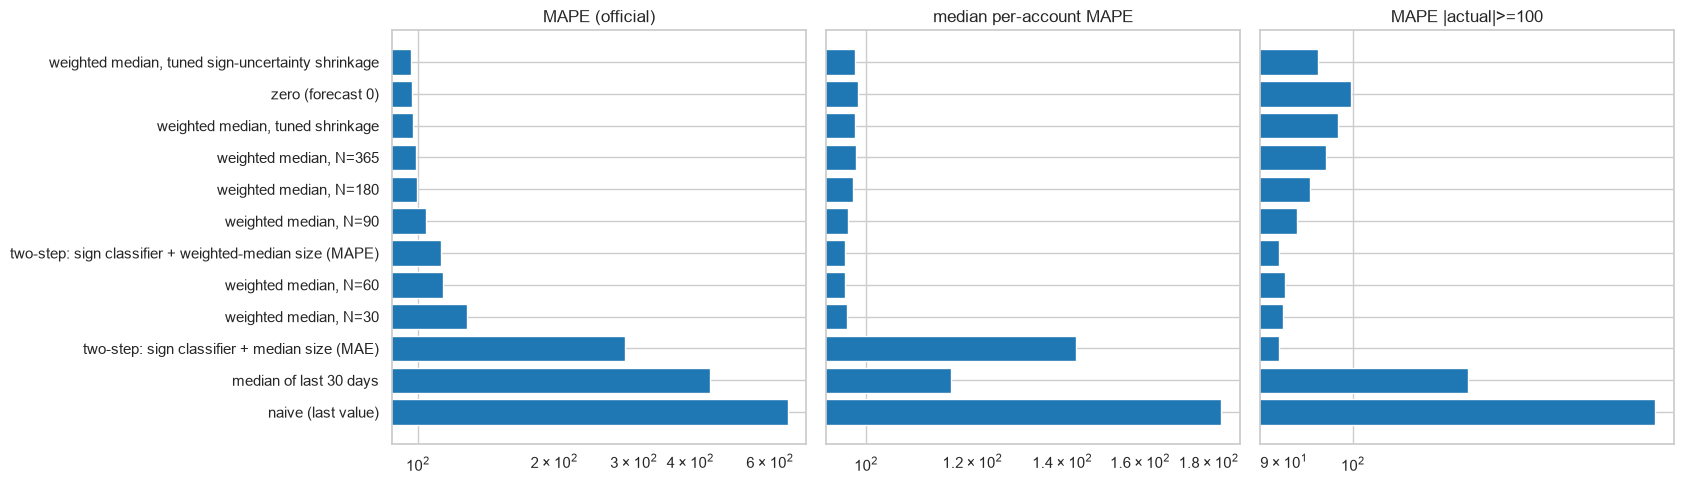

In [9]:
near = summary["near-zero / overdraft"]
verdict = pd.DataFrame({
    f"accepted vs {ref}": {m: passes_decision_rule(near.loc[m], near.loc[ref]) for m in near.index if m != ref}
    for ref in ("naive (last value)", "median of last 30 days", "zero (forecast 0)")})
display(verdict)
save_result(verdict, "02_decision_rule_near_zero", "Decision-rule verdict of every near-zero candidate against the two baselines")

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)      # the three measures of the decision rule
order = near.sort_values("MAPE (official)").index
for ax, m in zip(axes, METRICS):
    ax.barh(order, near.loc[order, m], color="tab:blue"); ax.set_title(m); ax.set_xscale("log")
axes[0].invert_yaxis(); plt.tight_layout(); plt.show()

The first result is the size of the gain. In the near-zero segment the last balance has an official MAPE of about
660% and the median of the last 30 days about 440%, while the weighted medians of the last 90 to 365 days are
around 100%. That confirms the main lesson of Sprint 1: the level matters more than anything else for these
accounts, and choosing it with the MAPE in mind removes about 85% of the official error.

The second result is a warning. The zero forecast scores just under 100% on the three measures (97% official), and
only one constant level gets below it: the weighted median of the last 180 to 365 days with the sign-uncertainty
shrinkage, at 96.5% official, which passes the decision rule against zero by less than one point. The plain tuned
shrinkage, whose factor ranges from 0 to 0.75 depending on the fold, stays just above zero (97.4%). For accounts
that cross zero all the time, no constant level is reliably within a factor of two of the true balance, so the best
constant costs almost as much as forecasting zero. The weighted medians do clearly better than zero only on the
balances of at least €100 (90 to 96% against almost 100%) and they do it by being right about sign and size on the
days when the balance is not tiny, at the price of a higher official score.

The WAPE shows how strange this floor is. A forecast of zero also has a WAPE of exactly 100%: it misses every euro of
every balance. The last balance and the median of the last 30 days miss about 70% of the euros, and the weighted
median of the last 30 days 64%, even though their percentage errors are far worse; the tuned shrinkage, which stays
close to zero, misses 97%. The zero floor is therefore a property of the MAPE, which caps the cost of
under-forecasting at 100% and leaves the cost of over-forecasting unbounded, and not a sign that zero is a good
forecast of the balance. The €1 added to the denominator does not change this: it removes the division by zero but
leaves balances of a few euros with huge percentage errors. We keep the official MAPE as the score that ranks models,
as decided in Sprint 1, but we read every result that relies on forecasting zero together with its WAPE.

The third result concerns the two-step idea. With the size predicted by a mean absolute error the official MAPE is
about 290%, because that loss ignores how costly it is to over-forecast a small balance. With a size chosen for the
MAPE it falls to about 113%, but that is still worse than the plain weighted median of the last 90 days (about 104%),
so the sign classifier did not add information beyond what the share of positive days already says. This does not
mean that sign prediction is useless in general. It means that a classifier built only on the recent sign pattern
of the account has nothing to learn from, and that any future version needs features that carry new information,
such as the calendar (the 8th, the end of the month) and the amounts of recurring payments.

The fourth result is about the other segment. On stable positive accounts the weighted median is worse than the
last balance or the median of 30 days on the typical account (11 to 25% against 9 to 11%), so leaning towards zero
should be reserved for the accounts that need it, which supports the segmented strategy decided in Sprint 1. The
official MAPE of that segment is large for every candidate except zero, because a few accounts classified as stable
in the past fall close to zero in the test window.

What we take forward is a floor and a question. The floor is that every model for near-zero accounts must beat a
100% MAPE, so the zero forecast becomes a reference of our decision rule. The question is how to do clearly better
than the floor, which a constant level can only just reach. That needs the within-month movement: the day of the month, the end-of-month
salary and the 8th, so that the forecast moves with the calendar instead of staying flat. Section 8 tests exactly
that, and section 9 returns to the stable accounts whose official score looked so odd.

## 8. Can the calendar beat the zero floor?

A constant level barely gets below the zero forecast for accounts that cross zero all the time. But balances do not
move at random:
salaries, pensions and debits come on fixed days of the month, so an account may be reliably positive on some days of
the month and reliably negative on others. We build a calendar profile for each account: for every day we want to
forecast, we take the balances the account had on the same day of the month (give or take two days) during the last
year, and keep their weighted median. This is the same MAPE-optimal estimator as before, now applied to days that
share a position in the month.

A profile alone still carries the risk of being wrong about the sign, which is what costs so much in percentage terms.
So we add a gate: we only use the profile on days when at least a share q of the past balances for that day of the
month have the same sign as the profile, and we forecast zero otherwise. The idea is to take a risk only when the
account has been consistent. The share q, and whether to halve the profile, are chosen on the two 30-day windows
before each cut-off, like in section 4.

In [10]:
dom = bal.columns.day.to_numpy()          # day of the month of every column of the matrix


def profile_parts(end, M=365, tol=2):
    """For the HORIZON days after column `end`: calendar-profile level and the share of past same-day balances that have
    the same sign as it. Uses columns before `end` only."""
    hist = np.arange(max(0, end - M), end)
    hd = dom[hist]
    T = B[:, :end]
    P = np.full((B.shape[0], HORIZON), np.nan)
    C = np.full_like(P, np.nan)
    for h in range(HORIZON):
        diff = np.abs(hd - dom[end + h])
        diff = np.minimum(diff, 31 - diff)                 # day 31 and day 1 are neighbours
        X = T[:, hist[diff <= tol]]
        med = weighted_median_inv(X)
        P[:, h] = med
        C[:, h] = np.nanmean(np.where(np.isnan(X), np.nan, np.sign(X) == np.sign(med)[:, None]), 1)
    return np.where(np.isfinite(P), P, T[:, -1:]), C


def gated(P, C, q, s):
    """Profile (times s) on days with sign agreement >= q, zero otherwise."""
    return np.where(C >= q, P * s, 0.0)


Q_GRID, S_GRID = [0.6, 0.7, 0.8, 0.9, 1.0], [1.0, 0.5]
Q_FIXED = 0.9
cal_rows, cal_params = [], []
for o in origins:
    e = cut[o]
    A = B[:, e:e + HORIZON]
    m = seg_by_fold[o] == "near-zero / overdraft"
    # tune q and s on the two inner windows
    inner = [(e - 60, profile_parts(e - 60)), (e - 30, profile_parts(e - 30))]
    scores = {}
    for q in Q_GRID:
        for sh in S_GRID:
            scores[(q, sh)] = sum(mape_official(B[m, ie:ie + HORIZON], gated(P, C, q, sh)[m]) for ie, (P, C) in inner)
    q_best, s_best = min(scores, key=scores.get)
    cal_params.append({"fold": str((o + pd.Timedelta(days=1)).date()), "q": q_best, "profile factor": s_best})
    P, C = profile_parts(e)
    cands = {"zero (forecast 0)": np.zeros_like(A),
             "weighted median, N=180 (constant)": np.repeat(fill(weighted_median_inv(B[:, e - 180:e]), B[:, e - 1])[:, None], HORIZON, 1),
             "calendar profile": P,
             "calendar profile, halved": 0.5 * P,
             f"gated calendar profile, q={Q_FIXED} (fixed)": gated(P, C, Q_FIXED, 1.0),
             "gated calendar profile, tuned": gated(P, C, q_best, s_best)}
    for name, f in cands.items():
        cal_rows.append({"fold": str((o + pd.Timedelta(days=1)).date()), "method": name, **evaluate(A[m], f[m])})
cal = pd.DataFrame(cal_rows)
cal_params = pd.DataFrame(cal_params)
cal_summary = cal.groupby("method")[METRICS].mean().sort_values("MAPE (official)")
display(cal_params)
display(cal_summary.round(1))
save_result(cal, "02_calendar_profile_by_fold", "Near-zero accounts: calendar-profile forecasts by fold", index=False)
save_result(cal_summary, "02_calendar_profile_summary", "Near-zero accounts: calendar-profile forecasts, mean over folds")
save_result(cal_params, "02_calendar_profile_tuned_parameters", "Gate threshold and profile factor chosen on the inner windows", index=False)

,fold,q,profile factor
0,2022-01-01,1.0,0.5
1,2022-09-03,1.0,0.5
2,2022-10-03,1.0,0.5
3,2022-11-02,1.0,1.0
4,2022-12-02,0.9,1.0


,MAPE (official),median per-account MAPE,MAPE |actual|>=100,WAPE
method,,,,
"gated calendar profile, q=0.9 (fixed)",92.9,94.9,88.1,94.5
"gated calendar profile, tuned",93.7,96.4,93.3,96.8
"calendar profile, halved",95.7,95.0,91.9,96.4
zero (forecast 0),97.2,98.7,99.7,100.0
"weighted median, N=180 (constant)",99.7,97.8,93.7,85.7
calendar profile,101.1,95.1,86.9,93.6


In [11]:
zero_ref = cal_summary.loc["zero (forecast 0)"]
cal_verdict = pd.Series({m: passes_decision_rule(cal_summary.loc[m], zero_ref) for m in cal_summary.index if m != zero_ref.name},
                        name="accepted against the zero forecast")
display(cal_verdict.to_frame())
pivot = cal.pivot(index="fold", columns="method", values="MAPE (official)")
wins = pivot.drop(columns="zero (forecast 0)").lt(pivot["zero (forecast 0)"], axis=0)
display(wins.sum().rename("folds (of 5) with a lower official MAPE than zero").to_frame())
display(pivot.round(1))
save_result(cal_verdict.to_frame(), "02_calendar_profile_decision_rule", "Decision-rule verdict against the zero forecast")

# share of near-zero account-days on which the gate lets the profile through
cover = {}
for o, (q_t, s_t) in zip(origins, zip(cal_params["q"], cal_params["profile factor"])):
    m = seg_by_fold[o] == "near-zero / overdraft"
    _, C = profile_parts(cut[o])
    cover[str((o + pd.Timedelta(days=1)).date())] = {"q=0.9 (fixed)": 100 * np.mean(C[m] >= Q_FIXED),
                                                     "tuned": 100 * np.mean(C[m] >= q_t)}
coverage = pd.DataFrame(cover).T
display(coverage.round(1).rename(columns=lambda c: f"% of days with a non-zero forecast, {c}"))
save_result(coverage, "02_calendar_profile_coverage", "Share (%) of near-zero account-days where the gated profile is used instead of zero")

,accepted against the zero forecast
"gated calendar profile, q=0.9 (fixed)",True
"gated calendar profile, tuned",True
"calendar profile, halved",True
"weighted median, N=180 (constant)",False
calendar profile,False


,folds (of 5) with a lower official MAPE than zero
method,
calendar profile,1
"calendar profile, halved",4
"gated calendar profile, q=0.9 (fixed)",5
"gated calendar profile, tuned",5
"weighted median, N=180 (constant)",2


method,calendar profile,"calendar profile, halved","gated calendar profile, q=0.9 (fixed)","gated calendar profile, tuned","weighted median, N=180 (constant)",zero (forecast 0)
fold,,,,,,
2022-01-01,99.6,92.7,91.1,93.9,99.8,97.6
2022-09-03,107.0,98.1,94.8,93.4,102.7,95.8
2022-10-03,103.0,97.2,91.7,93.5,96.6,97.2
2022-11-02,96.1,94.1,89.4,90.3,96.1,97.3
2022-12-02,99.9,96.4,97.3,97.3,103.2,98.0


,"% of days with a non-zero forecast, q=0.9 (fixed)","% of days with a non-zero forecast, tuned"
2022-01-01,26.5,11.4
2022-09-03,28.2,13.4
2022-10-03,28.3,13.4
2022-11-02,29.8,15.3
2022-12-02,30.7,30.7


The calendar helps, but only when we are careful with it. The profile on its own is worse than zero on the official
score (101% against 97%) and beats it in only one fold of five, because on the days when the account is not where its
history says it should be, the percentage error is large. Halving it brings it to 96%, below zero in four folds. The
gate does better still. Letting the profile through only when the past balances of that day of the month agree on the
sign brings the official MAPE to 93% to 94%, below the zero floor in all five folds, and lowers the MAPE on balances
of at least €100 to 88% to 93%. The version tuned on the inner windows chose the strictest gate (q = 1) in four folds
and q = 0.9 in December. The fixed gate of 0.9 is now slightly better than the tuned one on every measure (92.9%
against 93.7% official, 88% against 93% on the larger balances).

The gain is small, and it comes from few days. The tuned gate lets the profile through on only 11% to 15% of the
near-zero account-days (31% in December, where it chose q = 0.9), and the fixed gate of 0.9 on 27% to 31%; on the
rest the forecast is still zero. A gain of three to four points on a base of about 97 is real in the sense that it is
consistent across folds and passes our decision rule against the zero forecast, but it is modest, and the median MAPE
of the typical account improves only a little (96% for the tuned version and 95% for the fixed gate, against 99% for
zero). In practice the calendar tells us on which days it is safe to forecast a
value and on which days we should not. It does not make these accounts predictable.

## 9. Stable accounts that end near zero

In section 6 the stable positive accounts had an official MAPE well above 1 000% for every candidate except zero,
while the typical account was at 9 to 25%. Something must dominate the pooled score. We look at which accounts, and at whether they
could have been seen coming. For every fold we list the stable accounts whose balance gets within €100 of zero
during the test window, and the share of the segment's total percentage error that each account produces with the
last-balance forecast.

In [12]:
stable_rows = []
for o in origins:
    e = cut[o]
    T = B[:, :e]; A = B[:, e:e + HORIZON]
    m = seg_by_fold[o] == "stable positive"
    last = T[:, -1]
    R = T[:, -365:]
    err = ape(A, last[:, None])
    for i in np.where(m)[0]:
        stable_rows.append({"fold": str((o + pd.Timedelta(days=1)).date()), "account": bal.index[i], "last balance": last[i],
                            "median last year": np.nanmedian(R[i]), "min last year": np.nanmin(R[i]),
                            "min / median": np.nanmin(R[i]) / np.nanmedian(R[i]),
                            "min |actual|": np.nanmin(np.abs(A[i])), "error total": np.nansum(err[i]),
                            "ends near zero": np.nanmin(np.abs(A[i])) < NEAR_ZERO})
st = pd.DataFrame(stable_rows)
st["share of segment error"] = st["error total"] / st.groupby("fold")["error total"].transform("sum")
display(st.sort_values("share of segment error", ascending=False).head(8).round(2))
save_result(st, "02_stable_accounts_ending_near_zero", "Stable positive accounts: warning features and error contribution per fold", index=False)

,fold,account,last balance,median last year,min last year,min / median,min |actual|,error total,ends near zero,share of segment error
501,2022-11-02,328,133909.54,123438.43,109063.67,0.88,2.29,284922.02,True,1.00
276,2022-10-03,13,6022.65,5451.00,31.50,0.01,24.88,2622.82,True,0.73
149,2022-09-03,45,37911.90,36521.86,13966.38,0.38,808.27,647.69,False,0.42
48,2022-01-01,204,2200.16,12843.21,41.06,0.00,17.30,1072.67,True,0.40
68,2022-01-01,261,1671.09,6043.27,315.61,0.05,7.99,548.77,True,0.20
581,2022-12-02,137,11004.73,7824.49,1252.10,0.16,93.58,165.08,True,0.15
675,2022-12-02,445,173224.50,86375.80,69170.56,0.80,31042.32,89.62,False,0.08
219,2022-09-03,308,535.40,1421.74,310.76,0.22,11.62,102.85,True,0.07


One account in one fold produces practically all of the segment's error. Its balance, above €100 000, falls to a
few euros inside the window, and nothing in its history warns about it: its lowest balance of the last year was 88%
of its median. This is an event that no forecasting method could have predicted, and on its own it moves the pooled
score of that fold by about 100 percentage points. We cannot fix it, but we should keep it in mind when we compare
official scores, because a single account can decide a fold.

The other accounts that end near zero look different: their lowest balance of the last year had already been a small
fraction of their usual level. This suggests a warning rule for the stable accounts, which we test next: flag those
whose lowest balance of the last year was below 20% of their median.

In [13]:
flag_rows = []
for o in origins:
    e = cut[o]
    T = B[:, :e]; A = B[:, e:e + HORIZON]
    seg = seg_by_fold[o]
    R = T[:, -365:]
    ratio = np.nanmin(R, 1) / np.nanmedian(R, 1)
    base = seg == "stable positive"
    ends_near = np.nanmin(np.abs(A), 1) < NEAR_ZERO
    for name, mm in (("stable, all", base), ("stable, not flagged", base & (ratio >= 0.2)),
                     ("stable, flagged (min < 20% of median)", base & (ratio < 0.2))):
        flag_rows.append({"fold": str((o + pd.Timedelta(days=1)).date()), "group": name, "accounts": int(mm.sum()),
                          "ending near zero": int((mm & ends_near).sum()), **evaluate(A[mm], T[mm, -1:])})
flags = pd.DataFrame(flag_rows)
flag_summary = flags.groupby("group")[["accounts", "ending near zero"] + METRICS].mean()
display(flag_summary.round(1))
save_result(flag_summary, "02_stable_warning_flag", "Stable positive accounts split by a warning flag (lowest balance below 20% of the median), last-value forecast")

,accounts,ending near zero,MAPE (official),median per-account MAPE,MAPE |actual|>=100,WAPE
group,,,,,,
"stable, all",137.8,2.6,1423.7,9.2,27.9,6.9
"stable, flagged (min < 20% of median)",25.0,2.2,150.5,26.2,53.8,16.3
"stable, not flagged",112.8,0.4,1703.4,7.7,21.9,5.7


The threshold of 20% is a choice, so we check how the split behaves for other values before we keep it. A low
threshold flags only the accounts that came very close to zero; a high one flags many accounts that are simply
variable. For each value we count how many stable accounts are flagged, how many of the accounts that end near zero
in the test window were flagged beforehand, and the typical error of the accounts that stay in the stable group.

In [14]:
FLAG_GRID = [0.05, 0.1, 0.2, 0.3, 0.5]
sens_rows = []
for o in origins:
    e = cut[o]
    T = B[:, :e]; A = B[:, e:e + HORIZON]
    base = seg_by_fold[o] == "stable positive"
    R = T[:, -365:]
    ratio = np.nanmin(R, 1) / np.nanmedian(R, 1)
    ends_near = np.nanmin(np.abs(A), 1) < NEAR_ZERO
    for thr in FLAG_GRID:
        flagged = base & (ratio < thr)
        kept = base & ~flagged
        sens_rows.append({"fold": str((o + pd.Timedelta(days=1)).date()), "threshold": thr,
                          "flagged accounts": int(flagged.sum()),
                          "endings near zero caught (%)": 100 * (flagged & ends_near).sum() / max((base & ends_near).sum(), 1),
                          "kept: median per-account MAPE": evaluate(A[kept], T[kept, -1:])["median per-account MAPE"],
                          "flagged: median per-account MAPE": evaluate(A[flagged], T[flagged, -1:])["median per-account MAPE"]
                          if flagged.any() else np.nan})
flag_sens = pd.DataFrame(sens_rows).groupby("threshold").mean(numeric_only=True)
display(flag_sens.round(1))
save_result(flag_sens, "02_stable_flag_threshold_sensitivity", "Warning-flag threshold: accounts flagged, near-zero endings caught, typical error of kept and flagged accounts")

,flagged accounts,endings near zero caught (%),kept: median per-account MAPE,flagged: median per-account MAPE
threshold,,,,
0.05,9.6,48.3,8.8,27.5
0.10,14.8,65.0,8.3,29.2
0.20,25.0,80.0,7.7,26.2
0.30,35.4,90.0,7.0,24.0
0.50,59.8,90.0,5.5,20.3


The rule separates two very different groups. The 25 stable accounts per fold that are flagged have a typical error of
26% with the last balance, against 8% for the others, and they are the ones that end near zero more often (2.2 of the
2.6 accounts per fold that do so). So these accounts were not really stable, and the segment rule of Sprint 1, which
looks only at the average variation, lets them in. Among the accounts that are not flagged, the typical error falls from
9.2% to 7.7%. The official MAPE of the unflagged group is still very high, but that is the single €134 000 account
discussed above, which the flag cannot see.

We take two decisions forward. The segment rule gets an extra condition, so that a stable account must also have kept
its balance above 20% of its median during the last year, and the flagged accounts go to the near-zero strategy of
section 8. And we will report the official MAPE of the stable group together with its version without the largest
contributor, so that one unpredictable event does not decide a comparison between models.

## 10. The revised segmentation and the remaining segments

Section 9 showed that the stable group of Sprint 1 contains accounts that are not stable: those whose lowest balance of
the last year was below 20% of their median. We now add that condition to the rule. A flagged account is handled like
a near-zero account, and the stable group keeps only accounts that stayed clear of zero. Nothing else in the rule
changes. We then turn to the groups we have not yet studied, the volatile positive accounts and the dormant ones.

In [15]:
FLAG_RATIO = 0.2


def segments_v2(T):
    """Sprint 1 rule plus the warning flag: stable accounts whose lowest balance of the last year was below 20% of their
    median are moved to the near-zero group (strategy group 'near-zero / flagged')."""
    seg = segments(T).astype(object)
    R = T[:, -365:]
    ratio = np.nanmin(R, 1) / np.nanmedian(R, 1)
    seg[(seg == "stable positive") & (ratio < FLAG_RATIO)] = "near-zero / overdraft"
    return seg


seg2_by_fold = {o: segments_v2(B[:, :cut[o]]) for o in origins}
display(pd.DataFrame({str((o + pd.Timedelta(days=1)).date()): pd.Series(s).value_counts()
                      for o, s in seg2_by_fold.items()}).fillna(0).astype(int))

,2022-01-01,2022-09-03,2022-10-03,2022-11-02,2022-12-02
near-zero / overdraft,229,223,229,224,225
volatile positive,161,161,160,163,161
stable positive,110,116,111,113,114


The medium dataset has no dormant accounts at all: every account moves on more than 5% of the days. We keep the group
in the rule, because the large dataset may contain some, and we give it the simplest strategy, the last balance,
which is exact for an account that does not move. We could not test it here, and we say so in the conclusions.

For the volatile positive accounts we compare the level candidates of section 4, the calendar profile of section 8
and a global gradient-boosted model. The model is trained on the volatile accounts and predicts, for each day of the
horizon, the balance relative to the median of the last 30 days and scaled by the typical size of the account, which
makes the target stationary and comparable across accounts. Its loss is the MAPE itself: the absolute error on the
scaled target, weighted by the typical size over the true balance, with the weight capped to keep a few tiny balances
from dominating the fit. Its features describe the recent level and spread of the account, the day of the month and
the horizon, and the calendar profile value for that day.

In [16]:
WEIGHT_CAP = 10.0


def gbm_features(e, ids_mask, M=365, tol=2, extra=None):
    """Rows (one per account in mask and horizon day) for cut-off `e`: scaled recent-level features, calendar and profile.
    `extra(e)`, if given, returns more per-account features (a frame indexed by account position) joined to every row."""
    T = B[:, :e]
    typical = np.maximum(np.nanmedian(np.abs(T[:, -90:]), 1), EPS)
    ref = fill(np.nanmedian(T[:, -30:], 1), T[:, -1])
    P, C = profile_parts(e, M, tol)
    feats = {
        "last": (T[:, -1] - ref) / typical, "mean30": (np.nanmean(T[:, -30:], 1) - ref) / typical,
        "med90": (np.nanmedian(T[:, -90:], 1) - ref) / typical, "min30": (np.nanmin(T[:, -30:], 1) - ref) / typical,
        "max30": (np.nanmax(T[:, -30:], 1) - ref) / typical, "std30": np.nanstd(T[:, -30:], 1) / typical,
        "pos90": np.nanmean(T[:, -90:] > 0, 1), "ref": ref / typical,
    }
    ids = np.where(ids_mask)[0]
    rows = []
    for h in range(HORIZON):
        d = pd.DataFrame({k: v[ids] for k, v in feats.items()})
        d["horizon"] = h + 1
        d["dom"] = dom[e + h]
        d["dow"] = bal.columns[e + h].dayofweek
        d["profile"] = (P[ids, h] - ref[ids]) / typical[ids]
        d["agree"] = C[ids, h]
        d["acct"] = ids
        rows.append(d)
    X = pd.concat(rows, ignore_index=True)
    if extra is not None:
        X = X.join(extra(e), on="acct")
    return X, ref, typical


GBM_PARAMS = dict(objective="l1", n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=50,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1)


def gbm_forecast(e, train_mask, predict_mask, step=15, weighted=True, extra=None, **overrides):
    """Fit on past cut-offs of the accounts in train_mask, predict the HORIZON days after column e for predict_mask.
    `weighted` uses the MAPE weights; `overrides` change the LightGBM parameters (used in the comparison below)."""
    Xs, ys, ws = [], [], []
    for j in range(365, e - HORIZON + 1, step):
        X, ref, typical = gbm_features(j, train_mask, extra=extra)
        A = B[X["acct"].to_numpy(), j + X["horizon"].to_numpy() - 1]
        ok = np.isfinite(A) & np.isfinite(X["last"])
        y = (A - ref[X["acct"]]) / typical[X["acct"]]
        w = np.minimum(typical[X["acct"]] / (np.abs(A) + MAPE_OFFSET), WEIGHT_CAP)
        Xs.append(X[ok]); ys.append(y[ok]); ws.append(w[ok])
    X = pd.concat(Xs); y = np.concatenate(ys); w = np.concatenate(ws)
    feats = [c for c in X.columns if c != "acct"]
    model = lgb.LGBMRegressor(**{**GBM_PARAMS, **overrides})
    model.fit(X[feats], y, sample_weight=w if weighted else None)
    Xp, ref, typical = gbm_features(e, predict_mask, extra=extra)
    pred = model.predict(Xp[feats]) * typical[Xp["acct"]] + ref[Xp["acct"]]
    out = np.full((B.shape[0], HORIZON), np.nan)
    out[Xp["acct"].to_numpy(), Xp["horizon"].to_numpy() - 1] = pred
    return out


ZERO_GRID = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]      # forecasts smaller than this share of the typical size are set to zero


def zero_small(F, T, c):
    typical = np.maximum(np.nanmedian(np.abs(T[:, -90:]), 1), EPS)
    return np.where(np.abs(F) < c * typical[:, None], 0.0, F)


vol_rows = []
vol_fc = {}
vol_c = {}
for o in origins:
    e = cut[o]
    T = B[:, :e]; A = B[:, e:e + HORIZON]
    m = seg2_by_fold[o] == "volatile positive"
    last = T[:, -1]
    P, C = profile_parts(e)
    # threshold for zeroing small forecasts, tuned on the last 30 days before the cut-off with a model fitted before them
    F_in = gbm_forecast(e - HORIZON, m, m)
    A_in = B[:, e - HORIZON:e]
    # the official MAPE is minimised, but the typical-account MAPE may not get more than 10% worse than without zeroing
    scored = {c: evaluate(A_in[m], zero_small(F_in, B[:, :e - HORIZON], c)[m]) for c in ZERO_GRID}
    allowed = [c for c in ZERO_GRID if scored[c]["median per-account MAPE"] <= 1.10 * scored[0.0]["median per-account MAPE"]]
    c_best = min(allowed, key=lambda c: scored[c]["MAPE (official)"])
    vol_c[str((o + pd.Timedelta(days=1)).date())] = c_best
    F_gbm = gbm_forecast(e, m, m)
    vol_fc[o] = zero_small(F_gbm, T, c_best)
    cands = {k: np.repeat(v[:, None], HORIZON, 1) for k, v in level_candidates(T).items()}
    cands["calendar profile"] = P
    cands["gated calendar profile, q=0.9"] = gated(P, C, 0.9, 1.0)
    cands["global GBM (MAPE-weighted L1, scaled deviations)"] = F_gbm
    cands["global GBM, small forecasts zeroed (threshold tuned)"] = vol_fc[o]
    for name, f in cands.items():
        vol_rows.append({"fold": str((o + pd.Timedelta(days=1)).date()), "method": name, "accounts": int(m.sum()),
                         **evaluate(A[m], f[m])})
vol = pd.DataFrame(vol_rows)
print("zeroing thresholds chosen (share of typical size):", vol_c)
vol_summary = vol.groupby("method")[METRICS].mean().sort_values("MAPE (official)")
display(vol_summary.round(1))
save_result(vol, "02_volatile_positive_by_fold", "Volatile positive accounts: all candidates by fold", index=False)
save_result(vol_summary, "02_volatile_positive_summary", "Volatile positive accounts: mean over folds")

zeroing thresholds chosen (share of typical size): {'2022-01-01': 0.2, '2022-09-03': 0.1, '2022-10-03': 0.3, '2022-11-02': 0.1, '2022-12-02': 0.1}


,MAPE (official),median per-account MAPE,MAPE |actual|>=100,WAPE
method,,,,
"global GBM, small forecasts zeroed (threshold tuned)",89.3,52.7,51.0,27.4
"global GBM (MAPE-weighted L1, scaled deviations)",93.0,49.6,49.5,27.3
zero (forecast 0),99.5,99.8,99.8,100.0
"gated calendar profile, q=0.9",102.1,74.1,71.2,78.6
calendar profile,104.6,73.8,71.4,78.4
"weighted median, N=365",106.9,92.7,80.1,81.6
"weighted median, N=180",115.3,85.3,73.6,70.1
"weighted median, N=60",121.9,74.2,66.6,37.9
"weighted median, N=90",122.1,78.8,68.9,36.7


In [17]:
ref_v = vol_summary.loc["naive (last value)"]
vol_verdict = pd.DataFrame({
    f"accepted vs {ref}": {m: passes_decision_rule(vol_summary.loc[m], vol_summary.loc[ref]) for m in vol_summary.index if m != ref}
    for ref in ("naive (last value)", "median of last 30 days")})
display(vol_verdict)
save_result(vol_verdict, "02_volatile_positive_decision_rule", "Decision-rule verdict for the volatile positive candidates")

,accepted vs naive (last value),accepted vs median of last 30 days
"global GBM, small forecasts zeroed (threshold tuned)",True,True
"global GBM (MAPE-weighted L1, scaled deviations)",True,True
zero (forecast 0),False,False
"gated calendar profile, q=0.9",False,False
calendar profile,False,False
"weighted median, N=365",False,False
"weighted median, N=180",False,False
"weighted median, N=60",False,False
"weighted median, N=90",False,False
"weighted median, N=30",True,True


The tree model above is one configuration among many, so we check that its two main choices, the MAPE-weighted loss
and the size of the trees, are not arbitrary. We refit it with an unweighted absolute loss, with a squared loss, and
with smaller and larger trees, each time changing one thing and keeping the rest. The comparison is on the raw
forecasts, before small values are set to zero, so that the zeroing threshold does not hide differences between them.

In [18]:
GBM_VARIANTS = {"MAPE-weighted L1, 15 leaves (chosen)": {},
                "unweighted L1": {"weighted": False},
                "squared loss (L2), MAPE-weighted": {"objective": "l2"},
                "MAPE-weighted L1, 7 leaves": {"num_leaves": 7},
                "MAPE-weighted L1, 31 leaves": {"num_leaves": 31}}
gv_rows = []
for o in origins:
    e = cut[o]
    A = B[:, e:e + HORIZON]
    m = seg2_by_fold[o] == "volatile positive"
    for name, kw in GBM_VARIANTS.items():
        F = gbm_forecast(e, m, m, **kw)
        gv_rows.append({"fold": str((o + pd.Timedelta(days=1)).date()), "variant": name, **evaluate(A[m], F[m])})
gbm_var = pd.DataFrame(gv_rows).groupby("variant")[METRICS].mean().sort_values("MAPE (official)")
gbm_var["accepted vs chosen"] = [passes_decision_rule(gbm_var.loc[v], gbm_var.loc["MAPE-weighted L1, 15 leaves (chosen)"])
                                 for v in gbm_var.index]
display(gbm_var.round(1))
save_result(gbm_var, "02_gbm_variants", "Volatile accounts: GBM loss and tree-size variants (raw forecasts, mean over folds)")

,MAPE (official),median per-account MAPE,MAPE |actual|>=100,WAPE,accepted vs chosen
variant,,,,,
"MAPE-weighted L1, 15 leaves (chosen)",93.0,49.6,49.5,27.3,False
"MAPE-weighted L1, 31 leaves",93.9,49.9,48.9,24.3,False
"MAPE-weighted L1, 7 leaves",95.0,52.0,50.4,26.3,False
"squared loss (L2), MAPE-weighted",115.1,48.3,50.6,32.2,False
unweighted L1,173.4,49.2,59.7,21.1,False


The table answers two questions. The first is whether weighting the loss by the MAPE matters: the unweighted absolute
loss and the squared loss treat a euro of error on a small balance like a euro on a large one, so if our reasoning in
section 4 is right they should do worse on the official MAPE, and the squared loss should suffer most from the heavy
tails of section 6 of Sprint 1. The second is whether the size of the trees was a lucky guess: if the smaller and
larger trees land close to the chosen configuration, the model is not sensitive to it and there is no reason to tune
it further on folds this few. The last column applies our decision rule to each variant against the chosen one; a
variant that passed it would replace the configuration used in the rest of the notebook in the next iteration.

Both expectations hold. Without the MAPE weights the official score gets much worse (173% for the unweighted absolute
loss and 115% for the squared loss, against 93% for the chosen model), and trees of 7 or 31 leaves land close to the
chosen 15 (95% and 94%). No variant passes the rule, so the configuration stays as it is.

A last variant asks whether automatic features would help the tree model, as they are often said to. We use the
`tsfresh` package: for every account and cut-off it computes several hundred statistics of the last 90 days of the
balance, scaled like the target. We keep the 30 most relevant, chosen by the relevance test of `tsfresh` (with a 5%
false discovery rate) on cut-offs whose 30-day target ends before the first fold, so that no test window is used, and
we add them to the features of the model. The rest is unchanged, including the zeroing of small forecasts.

The experiment adds about ten minutes on the medium dataset, and much more on the large one, so it only runs when
`RUN_TSFRESH_GBM` is set to True in the first cell. When we ran it on the medium dataset, the automatic features took
44% of the splits of the trees but did not improve the forecasts: 107.2% official, 50.4% typical account and 49.4% on
balances of at least €100 against 107.5%, 50.3% and 49.8% without them, and 99.3% against 97.7% official once small
forecasts are set to zero, with a worse WAPE in both cases. These numbers were measured before the €1 was added to the
MAPE denominator, and the experiment has not been run again since. The decision rule rejected them in both versions, so the
model keeps its hand-made features, which also keeps the run short.

In [19]:
TSF_WIN, TSF_TOP_K = 90, 30


def tsf_window_long(j, ids):
    """Long frame of the last TSF_WIN days before column j, scaled like the GBM target."""
    T = pd.DataFrame(B[ids, j - TSF_WIN:j]).ffill(axis=1).to_numpy()
    typical = np.maximum(np.nanmedian(np.abs(B[ids, j - 90:j]), 1), EPS)
    ref = fill(np.nanmedian(B[ids, j - 30:j], 1), B[ids, j - 1])
    Z = (T - ref[:, None]) / typical[:, None]
    return pd.DataFrame({"id": np.repeat(ids, TSF_WIN), "t": np.tile(np.arange(TSF_WIN), len(ids)),
                         "y": Z.ravel()}).dropna()


def tsf_extract(j, ids, **kw):
    X = extract_features(tsf_window_long(j, ids), column_id="id", column_sort="t", column_value="y",
                         n_jobs=4, disable_progressbar=True, **kw)
    X.index = X.index.astype(int)
    return X.replace([np.inf, -np.inf], np.nan)


if RUN_TSFRESH_GBM:
    vol_any = np.logical_or.reduce([seg2_by_fold[o] == "volatile positive" for o in origins])
    tsf_ids = np.where(vol_any)[0]
    # selection on cut-offs whose target ends before the first fold
    sel_X, sel_y = [], []
    for j in range(365, min(cut.values()) - HORIZON + 1, 15):
        X = tsf_extract(j, tsf_ids, default_fc_parameters=EfficientFCParameters())
        typical = np.maximum(np.nanmedian(np.abs(B[:, j - 90:j]), 1), EPS)
        ref = fill(np.nanmedian(B[:, j - 30:j], 1), B[:, j - 1])
        y = (np.nanmedian(B[:, j:j + HORIZON], 1) - ref) / typical
        sel_X.append(X); sel_y.append(pd.Series(y[X.index], index=X.index))
    X = pd.concat(sel_X, ignore_index=True); y = pd.concat(sel_y, ignore_index=True)
    X = X.loc[:, (X.notna().mean() > 0.9) & (X.nunique() > 1)]
    X = X.fillna(X.median())
    rel = calculate_relevance_table(X[y.notna()], y[y.notna()], ml_task="regression")
    tsf_chosen = list(rel[rel.relevant].sort_values("p_value").feature[:TSF_TOP_K])
    print(f"{X.shape[1]} usable tsfresh features, {int(rel.relevant.sum())} relevant, {len(tsf_chosen)} kept")
    tsf_kind = tsf_settings.from_columns(tsf_chosen)
    tsf_cache = {}

    def tsf_extra(j):
        """Selected tsfresh features at cut-off j, with names LightGBM accepts."""
        if j not in tsf_cache:
            F = tsf_extract(j, tsf_ids, kind_to_fc_parameters=tsf_kind).reindex(columns=tsf_chosen)
            tsf_cache[j] = F.set_axis([f"tsf_{i:02d}" for i in range(F.shape[1])], axis=1)
        return tsf_cache[j]

    tsf_rows = []
    for o in origins:
        e = cut[o]
        T = B[:, :e]; A = B[:, e:e + HORIZON]
        m = seg2_by_fold[o] == "volatile positive"
        fold = str((o + pd.Timedelta(days=1)).date())
        F_in = gbm_forecast(e - HORIZON, m, m, extra=tsf_extra)
        A_in = B[:, e - HORIZON:e]
        scored = {c: evaluate(A_in[m], zero_small(F_in, B[:, :e - HORIZON], c)[m]) for c in ZERO_GRID}
        allowed = [c for c in ZERO_GRID
                   if scored[c]["median per-account MAPE"] <= 1.10 * scored[0.0]["median per-account MAPE"]]
        c_best = min(allowed, key=lambda c: scored[c]["MAPE (official)"])
        F = gbm_forecast(e, m, m, extra=tsf_extra)
        tsf_rows.append({"fold": fold, "method": "GBM + tsfresh features", **evaluate(A[m], F[m])})
        tsf_rows.append({"fold": fold, "method": "GBM + tsfresh features, small forecasts zeroed",
                         **evaluate(A[m], zero_small(F, T, c_best)[m])})
    tsf_cmp = pd.concat([pd.DataFrame(tsf_rows).groupby("method")[METRICS].mean(),
                         gbm_var.loc[["MAPE-weighted L1, 15 leaves (chosen)"], METRICS],
                         vol_summary.loc[["global GBM, small forecasts zeroed (threshold tuned)"], METRICS]])
    tsf_cmp["accepted vs the same model without tsfresh"] = [
        passes_decision_rule(tsf_cmp.iloc[0], tsf_cmp.iloc[2]), passes_decision_rule(tsf_cmp.iloc[1], tsf_cmp.iloc[3]),
        np.nan, np.nan]
    display(tsf_cmp.round(1))
    save_result(tsf_cmp, "02_gbm_tsfresh", "Volatile accounts: GBM with and without tsfresh features (mean over folds)")
else:
    tsf_cmp = None
    print("tsfresh experiment skipped (RUN_TSFRESH_GBM = False); the results of our last run are described above")

tsfresh experiment skipped (RUN_TSFRESH_GBM = False); the results of our last run are described above


## 11. Do the classical models do better?

So far the stable accounts have been forecast with the last balance and the volatile ones with a global tree model.
Neither is a time series model in the sense of the course, and Sprint 1 gave us reasons to expect that one could
help: the daily changes are stationary (d = 1), the balance reverts towards a level over a month, and activity follows
the week, since balances only move on business days. We therefore fit to every stable and volatile account an
exponential smoothing model and an ARIMA model, each chosen automatically per account by information criterion, with
a weekly season of 7 days. The ETS has additive errors and an additive weekly season, with the trend (none, additive
or damped) chosen by AICc, because balances can be negative and a multiplicative model needs them positive. The ARIMA
chooses its orders, the differencing and the seasonal part by the KPSS and seasonal tests and AICc. Both are fitted on
the last year before each cut-off, so that a level shift of two years ago does not pull the forecast, and run in
parallel over accounts, which is what makes them affordable on the large dataset. To check that the weekly season is
worth its cost, we also fit both models without it.

The monthly cycle of salaries and pensions is not in these models: a season of 30 days on daily data would make
the seasonal ARIMA very expensive and the month does not have a fixed length. The calendar is what the gated profile
and the tree model use instead, so this section tells us how far the classical models get without it.

In [20]:
CLASSICAL = {"ets": "ETS (additive, weekly season)", "arima": "ARIMA (auto, weekly season)",
             "ets_ns": "ETS (additive, no season)", "arima_ns": "ARIMA (auto, no season)"}


def classical_forecasts(e, mask):
    """AutoETS and AutoARIMA fitted per account (accounts in mask) on the FIT_DAYS days before column e."""
    out = {name: np.full((B.shape[0], HORIZON), np.nan) for name in CLASSICAL.values()}
    ids = np.where(mask)[0]
    if len(ids) > 0:
        W = pd.DataFrame(B[ids, e - FIT_DAYS:e]).ffill(axis=1).to_numpy()
        long = pd.DataFrame({"unique_id": np.repeat(ids, FIT_DAYS), "ds": np.tile(bal.columns[e - FIT_DAYS:e], len(ids)),
                             "y": W.ravel()}).dropna()
        sf = StatsForecast(models=[AutoETS(season_length=7, model="AZA", alias="ets"),
                                   AutoARIMA(season_length=7, alias="arima"),
                                   AutoETS(season_length=1, model="AZN", alias="ets_ns"),
                                   AutoARIMA(season_length=1, alias="arima_ns")],
                           freq="D", n_jobs=N_JOBS, fallback_model=Naive())
        fc = sf.forecast(h=HORIZON, df=long)
        fc = fc.reset_index() if "unique_id" not in fc.columns else fc
        for alias, name in CLASSICAL.items():
            M = fc.pivot(index="unique_id", columns="ds", values=alias)
            out[name][M.index.to_numpy().astype(int)] = M.to_numpy()
    last = B[:, e - 1]
    # accounts without enough history keep their last balance
    return {k: np.where(np.isfinite(v), v, last[:, None]) for k, v in out.items()}


def metrics_without_top(A, F):
    """Scores after removing the account with the largest total percentage error."""
    err = ape(A, F)
    keep = np.arange(len(A)) != np.nanargmax(np.nansum(err, 1))
    return evaluate(A[keep], F[keep])


cls_fc, cls_rows = {}, []
for o in origins:
    e = cut[o]
    T = B[:, :e]; A = B[:, e:e + HORIZON]
    seg = seg2_by_fold[o]
    fit_mask = np.isin(seg, ["stable positive", "volatile positive"])
    cls_fc[o] = classical_forecasts(e, fit_mask)
    for sname in ("stable positive", "volatile positive"):
        m = seg == sname
        cands = {"naive (last value)": np.repeat(T[:, -1:], HORIZON, 1),
                 "median of last 30 days": np.repeat(fill(np.nanmedian(T[:, -30:], 1), T[:, -1])[:, None], HORIZON, 1),
                 **cls_fc[o]}
        if sname == "volatile positive":
            cands["global GBM, small forecasts zeroed (threshold tuned)"] = vol_fc[o]
        for name, f in cands.items():
            fold = str((o + pd.Timedelta(days=1)).date())
            cls_rows.append({"fold": fold, "segment": sname, "method": name, "version": "all accounts",
                             **evaluate(A[m], f[m])})
            cls_rows.append({"fold": fold, "segment": sname, "method": name, "version": "without the largest contributor",
                             **metrics_without_top(A[m], f[m])})
cls = pd.DataFrame(cls_rows)
cls_summary = cls.groupby(["version", "segment", "method"])[METRICS].mean()
display(cls_summary.round(1))
save_result(cls, "02_classical_by_fold", "ETS and ARIMA vs baselines (and the GBM for volatile accounts), by fold", index=False)
save_result(cls_summary, "02_classical_summary", "ETS and ARIMA vs baselines, by segment, mean over folds")

MAPE (official)  \
version                         segment           method                                                                
all accounts                    stable positive   ARIMA (auto, no season)                                      1731.8   
                                                  ARIMA (auto, weekly season)                                  1732.3   
                                                  ETS (additive, no season)                                    1726.4   
                                                  ETS (additive, weekly season)                                1726.6   
                                                  median of last 30 days                                       1710.3   
                                                  naive (last value)                                           1703.4   
                                volatile positive ARIMA (auto, no season)                                       237.9   
                                                  ARIMA (auto, weekly season)                                   237.8   
                                                  ETS (additive, no season)                                     241.9   
                                                  ETS (additive, weekly season)                                 251.7   
                                                  global GBM, small forecasts zeroed (threshold t...             89.3   
                                                  median of last 30 days                                        203.9   
                                                  naive (last value)                                            242.7   
without the largest contributor stable positive   ARIMA (auto, no season)                                        15.9   
                                                  ARIMA (auto, weekly season)                                    16.2   
                                                  ETS (additive, no season)                                      16.8   
                                                  ETS (additive, weekly season)                                  16.9   
                                                  median of last 30 days                                         18.6   
                                                  naive (last value)                                             16.9   
                                volatile positive ARIMA (auto, no season)                                       198.6   
                                                  ARIMA (auto, weekly season)                                   198.6   
                                                  ETS (additive, no season)                                     201.2   
                                                  ETS (additive, weekly season)                                 210.4   
                                                  global GBM, small forecasts zeroed (threshold t...             71.6   
                                                  median of last 30 days                                        173.5   
                                                  naive (last value)                                            202.0   

                                                                                                      median per-account MAPE  \
version                         segment           method                                                                        
all accounts                    stable positive   ARIMA (auto, no season)                                                 7.1   
                                                  ARIMA (auto, weekly season)                                             7.2   
                                                  ETS (additive, no season)                                               7.6   
                                                  ETS (additive, wee

In [21]:
refs = {"stable positive": ["naive (last value)", "median of last 30 days"],
        "volatile positive": ["naive (last value)", "median of last 30 days",
                              "global GBM, small forecasts zeroed (threshold tuned)"]}
cls_verdict = {}
for version in ("all accounts", "without the largest contributor"):
    for sname, rlist in refs.items():
        tab = cls_summary.loc[(version, sname)]
        cls_verdict[(version, sname)] = pd.DataFrame(
            {f"accepted vs {r}": {m: passes_decision_rule(tab.loc[m], tab.loc[r]) for m in CLASSICAL.values()}
             for r in rlist})
cls_verdict_df = pd.concat(cls_verdict, names=["version", "segment", "method"])
display(cls_verdict_df)
save_result(cls_verdict_df, "02_classical_decision_rule",
            "Decision-rule verdict of ETS and ARIMA, by segment, with and without the largest contributor")

# A model is adopted when it passes the rule against every reference once the largest contributor of each fold is left
# out: section 9 showed that this account is unpredictable for any method and decides the official score on its own.
DECIDING_VERSION = "without the largest contributor"


def chosen_model(sname, incumbent):
    """The classical model with the lowest official MAPE among those accepted against every reference, else incumbent."""
    v = cls_verdict[(DECIDING_VERSION, sname)]
    ok = [m for m in CLASSICAL.values() if v.loc[m].all()]
    return min(ok, key=lambda m: cls_summary.loc[(DECIDING_VERSION, sname, m), "MAPE (official)"]) if ok else incumbent


STABLE_MODEL = chosen_model("stable positive", "naive (last value)")
VOLATILE_MODEL = chosen_model("volatile positive", "global GBM, small forecasts zeroed (threshold tuned)")
print("stable accounts ->", STABLE_MODEL, "| volatile accounts ->", VOLATILE_MODEL)

accepted vs naive (last value)  \
version                         segment           method                                                          
all accounts                    stable positive   ETS (additive, weekly season)                           False   
                                                  ARIMA (auto, weekly season)                             False   
                                                  ETS (additive, no season)                               False   
                                                  ARIMA (auto, no season)                                 False   
                                volatile positive ETS (additive, weekly season)                           False   
                                                  ARIMA (auto, weekly season)                              True   
                                                  ETS (additive, no season)                                True   
                                                  ARIMA (auto, no season)                                  True   
without the largest contributor stable positive   ETS (additive, weekly season)                           False   
                                                  ARIMA (auto, weekly season)                              True   
                                                  ETS (additive, no season)                                True   
                                                  ARIMA (auto, no season)                                  True   
                                volatile positive ETS (additive, weekly season)                           False   
                                                  ARIMA (auto, weekly season)                              True   
                                                  ETS (additive, no season)                                True   
                                                  ARIMA (auto, no season)                                  True   

                                                                                 accepted vs median of last 30 days  \
version                         segment           method                                                              
all accounts                    stable positive   ETS (additive, weekly season)                               False   
                                                  ARIMA (auto, weekly season)                                 False   
                                                  ETS (additive, no season)                                   False   
                                                  ARIMA (auto, no season)                                     False   
                                volatile positive ETS (additive, weekly season)                               False   
                                                  ARIMA (auto, weekly season)                                 False   
                                                  ETS (additive, no season)                                   False   
                                                  ARIMA (auto, no season)                                     False   
without the largest contributor stable positive   ETS (additive, weekly season)                                True   
                                                  ARIMA (auto, weekly season)                                  True   
                                                  ETS (additive, no season)                                    True   
                                                  ARIMA (auto, no season)                                      True   
                                volatile positive ETS (additive, weekly season)                               False   
                                                  ARIMA (auto, weekly season)                                 False   
                                                  ETS (additive, no season)                               

stable accounts -> ARIMA (auto, no season) | volatile accounts -> global GBM, small forecasts zeroed (threshold tuned)


On the stable accounts the ARIMA is the best model we have tried, but only by a little, and the weekly season does not
pay for itself: the ARIMA without it is slightly better than with it. Its typical-account error is 7.1% (7.2% with the
season) against 7.7% for the last balance, and its error on balances of at least €100 is 20.4% against 21.9%. On all
accounts it is rejected, because its official MAPE is 1 732% against 1 703%, and that score is decided by the one
account of section 9 that falls from €134 000 to a few euros. Once the largest contributor of each fold is left out
the picture is clear: 15.9% against 16.9% official, and the ARIMA passes the rule against both baselines, as the
ETS without season also does by a smaller margin (16.8%). Since that single account is unpredictable for any method,
we adopt the ARIMA without season for the stable accounts and keep reporting both versions. The ETS ends up almost
identical to the last balance (typical account 7.5% to 7.8%), which is what simple exponential smoothing becomes
when its smoothing weight is close to one, and it is what Sprint 1 led us to expect from balances that behave like a
random walk from one day to the next.

On the volatile accounts the classical models help less than the tree model by a wide margin. The ARIMA improves on
the last balance (official 238% against 243%, typical account 64% against 67%) and passes the rule against it, but
the global model of section 10 reaches 89% and 53%. The difference is the calendar: the tree model knows the day of
the month and the calendar profile, while a weekly ARIMA does not see the salary and the pension coming. So the
volatile accounts stay with the tree model, and the course models earn their place where the balance is far from zero
and the problem is a matter of small corrections to the level.

## 12. Putting the strategies together

We now have a strategy for each group. Accounts in the near-zero group, which now includes the flagged ones, get the
gated calendar profile of section 8, with its gate tuned on the two windows before each cut-off. Stable and volatile
accounts get the model chosen in section 11. Dormant accounts, which do not appear in the medium dataset, get the
last balance. We score the whole pipeline on all accounts, next to the baselines of Sprint 1 and the zero forecast,
and we also report the scores without the single account that contributes most to the error in each fold, since
section 9 showed that one account can decide a fold.

The first version of this pipeline, which we ran before writing this section, had a clear weakness: inside the
near-zero group some accounts are perfectly predictable with their last balance, and forcing the gated profile (or
zero) on them cost about 100% each, which made the typical account worse than with the last balance. So the pipeline
now makes one more choice, per account and without looking at the test window: for every near-zero account it
compares the last balance, the guarded profile and zero on the two 30-day windows before the cut-off, and keeps the
one with the lowest MAPE for that account. We report the pipeline with and without this choice, so that its effect
can be read directly.

In [22]:
def tune_gate(e, m):
    """Gate threshold and profile factor for the cut-off e, tuned on the two windows before it using accounts in m."""
    inner = [(e - 60, profile_parts(e - 60)), (e - 30, profile_parts(e - 30))]
    scores = {(q, sh): sum(mape_official(B[m, ie:ie + HORIZON], gated(P, C, q, sh)[m]) for ie, (P, C) in inner)
              for q in Q_GRID for sh in S_GRID}
    return min(scores, key=scores.get)


def recent_range_guard(G, T, days=30):
    """Keep non-zero forecasts inside the range of the last `days` balances. A profile built on the last year knows
    nothing about a level shift that has just happened."""
    lo, hi = np.nanmin(T[:, -days:], 1)[:, None], np.nanmax(T[:, -days:], 1)[:, None]
    return np.where(G != 0, np.clip(G, lo, hi), 0.0)


def level_shift_guard(G, T, low=0.2, high=5.0):
    """Forecast zero for accounts whose balance of the last 7 days is far from the median of the last year (ratio below
    `low` or above `high`): a level shift has just happened and the yearly profile is stale."""
    ratio = np.abs(np.nanmedian(T[:, -7:], 1)) / np.maximum(np.abs(np.nanmedian(T[:, -365:], 1)), EPS)
    return np.where(((ratio < low) | (ratio > high))[:, None], 0.0, G)


NEAR_OPTIONS = ["guarded profile", "zero", "last value"]      # order also breaks ties: the profile first


def near_options(e, q, sh, guard=True):
    """The three near-zero forecasts for the HORIZON days after column e, stacked as (accounts, HORIZON, 3)."""
    T = B[:, :e]
    P, C = profile_parts(e)
    G = gated(P, C, q, sh)
    G = level_shift_guard(recent_range_guard(G, T), T) if guard else G
    return np.stack([G, np.zeros_like(G), np.repeat(T[:, -1:], HORIZON, 1)], axis=2)


def near_choice(e, q, sh):
    """Per account: index of the near-zero option with the lowest MAPE summed over the two windows before e."""
    score = np.zeros((B.shape[0], len(NEAR_OPTIONS)))
    for ie in (e - 60, e - 30):
        opts = near_options(ie, q, sh)
        Ain = B[:, ie:ie + HORIZON]
        for k in range(len(NEAR_OPTIONS)):
            score[:, k] += np.nan_to_num(mape_per_account(Ain, opts[:, :, k]), nan=0.0)
    return score.argmin(1)


def pipeline_forecast(o, guard=True, choice=True):
    e = cut[o]
    T = B[:, :e]
    seg = seg2_by_fold[o]
    F = np.repeat(T[:, -1:], HORIZON, 1).astype(float)                 # dormant: last balance
    near = seg == "near-zero / overdraft"
    q, sh = tune_gate(e, near)
    opts = near_options(e, q, sh, guard)
    pick = near_choice(e, q, sh) if choice else np.zeros(B.shape[0], dtype=int)
    F_near = np.take_along_axis(opts, pick[:, None, None].repeat(HORIZON, 1), axis=2)[:, :, 0]
    F[near] = F_near[near]
    model_fc = {"naive (last value)": np.repeat(T[:, -1:], HORIZON, 1),
                "global GBM, small forecasts zeroed (threshold tuned)": vol_fc[o], **cls_fc[o]}
    for sname, model in (("stable positive", STABLE_MODEL), ("volatile positive", VOLATILE_MODEL)):
        m = seg == sname
        F[m] = model_fc[model][m]
    return F, np.where(near, pick, -1)


PIPE ="segment pipeline, per-account choice"
PIPE_V1 = "segment pipeline, no per-account choice"
PIPE_NOGUARD = "segment pipeline, no choice and no guards"
all_rows, seg_rows, pick_rows = [], [], []
for o in origins:
    e = cut[o]
    T = B[:, :e]; A = B[:, e:e + HORIZON]
    fold = str((o + pd.Timedelta(days=1)).date())
    F_pipe, pick = pipeline_forecast(o)
    pick_rows.append({"fold": fold, **{opt: int((pick == k).sum()) for k, opt in enumerate(NEAR_OPTIONS)}})
    systems = {"zero (forecast 0)": np.zeros_like(A),
               "naive (last value)": np.repeat(T[:, -1:], HORIZON, 1),
               "median of last 30 days": np.repeat(fill(np.nanmedian(T[:, -30:], 1), T[:, -1])[:, None], HORIZON, 1),
               PIPE: F_pipe,
               PIPE_V1: pipeline_forecast(o, choice=False)[0],
               PIPE_NOGUARD: pipeline_forecast(o, guard=False, choice=False)[0]}
    for name, F in systems.items():
        all_rows.append({"fold": fold, "system": name, "version": "all accounts", **evaluate(A, F)})
        all_rows.append({"fold": fold, "system": name, "version": "without the largest contributor", **metrics_without_top(A, F)})
    for sname in ("near-zero / overdraft", "stable positive", "volatile positive"):
        mm = seg2_by_fold[o] == sname
        for name in ("naive (last value)", PIPE, PIPE_V1, PIPE_NOGUARD):
            seg_rows.append({"fold": fold, "segment": sname, "system": name, **evaluate(A[mm], systems[name][mm])})
overall = pd.DataFrame(all_rows)
by_segment = pd.DataFrame(seg_rows).groupby(["segment", "system"])[METRICS].mean()
picks = pd.DataFrame(pick_rows).set_index("fold")
print("near-zero accounts by chosen option:")
display(picks)
for v in ("all accounts", "without the largest contributor"):
    print(f"\n=== {v} ===")
    display(overall[overall.version == v].groupby("system")[METRICS].mean().sort_values("MAPE (official)").round(1))
print("\n=== by segment ===")
display(by_segment.round(1))
for m in ("MAPE (official)", "median per-account MAPE"):
    print(f"\n=== {m} by fold, all accounts ===")
    display(overall[overall.version == "all accounts"].pivot(index="fold", columns="system", values=m).round(1))
save_result(overall, "02_pipeline_by_fold", "Segment pipeline vs baselines on all accounts, by fold, with and without the largest contributor", index=False)
save_result(by_segment, "02_pipeline_by_segment", "Segment pipeline vs last value, by segment (mean over folds)")
save_result(picks, "02_near_zero_choice_counts", "Near-zero accounts per fold by the option chosen on the inner windows")

near-zero accounts by chosen option:


,guarded profile,zero,last value
fold,,,
2022-01-01,167,16,46
2022-09-03,163,18,42
2022-10-03,174,14,41
2022-11-02,155,20,49
2022-12-02,156,15,54



=== all accounts ===


,MAPE (official),median per-account MAPE,MAPE |actual|>=100,WAPE
system,,,,
zero (forecast 0),98.7,99.8,99.8,100.0
"segment pipeline, no per-account choice",463.9,72.4,55.5,17.3
"segment pipeline, per-account choice",472.4,69.0,56.3,16.8
naive (last value),735.8,68.1,88.3,11.7
"segment pipeline, no choice and no guards",939.5,75.4,57.1,34.2
median of last 30 days,2074.9,66.0,71.2,13.9



=== without the largest contributor ===


,MAPE (official),median per-account MAPE,MAPE |actual|>=100,WAPE
system,,,,
"segment pipeline, no per-account choice",68.6,72.3,53.8,17.2
"segment pipeline, no choice and no guards",72.3,75.4,56.0,34.1
"segment pipeline, per-account choice",77.2,69.0,54.6,16.6
zero (forecast 0),98.7,99.8,99.8,100.0
median of last 30 days,244.0,65.8,68.0,13.5
naive (last value),320.5,67.8,79.2,11.5


... (2 outputs left out)


=== MAPE (official) by fold, all accounts ===


system,median of last 30 days,naive (last value),"segment pipeline, no choice and no guards","segment pipeline, no per-account choice","segment pipeline, per-account choice",zero (forecast 0)
fold,,,,,,
2022-01-01,266.8,474.3,88.3,82.9,92.2,98.9
2022-09-03,208.4,342.9,77.2,75.9,90.2,98.1
2022-10-03,202.3,428.8,71.4,83.3,95.6,98.7
2022-11-02,2374.0,2195.1,2002.7,2001.0,2007.0,98.7
2022-12-02,7322.9,237.9,2458.0,76.2,76.9,99.0



=== median per-account MAPE by fold, all accounts ===


system,median of last 30 days,naive (last value),"segment pipeline, no choice and no guards","segment pipeline, no per-account choice","segment pipeline, per-account choice",zero (forecast 0)
fold,,,,,,
2022-01-01,72.9,70.8,79.5,77.4,73.7,99.7
2022-09-03,72.2,66.2,74.3,70.1,66.4,99.8
2022-10-03,68.5,74.8,78.4,77.7,76.6,99.8
2022-11-02,60.4,68.7,71.2,67.3,62.7,99.7
2022-12-02,55.8,60.0,73.8,69.4,65.8,99.8


In [23]:
verdicts = {}
for v in ("all accounts", "without the largest contributor"):
    sm = overall[overall.version == v].groupby("system")[METRICS].mean()
    for sysname in (PIPE, PIPE_V1):
        verdicts[(v, sysname)] = {f"vs {ref}": passes_decision_rule(sm.loc[sysname], sm.loc[ref])
                                  for ref in ("naive (last value)", "median of last 30 days", "zero (forecast 0)")}
pipe_verdict = pd.DataFrame(verdicts).T
pipe_verdict.index.names = ["version", "system"]
display(pipe_verdict)
save_result(pipe_verdict, "02_pipeline_decision_rule", "Decision-rule verdict of the segment pipeline, with and without the per-account choice")

vs naive (last value)  vs median of last 30 days  \
version                         system                                                                                      
all accounts                    segment pipeline, per-account choice                     False                      False   
                                segment pipeline, no per-account choice                  False                      False   
without the largest contributor segment pipeline, per-account choice                     False                      False   
                                segment pipeline, no per-account choice                  False                      False   

                                                                         vs zero (forecast 0)  
version                         system                                                         
all accounts                    segment pipeline, per-account choice                    False  
                                segment pipeline, no per-account choice                 False  
without the largest contributor segment pipeline, per-account choice                     True  
                                segment pipeline, no per-account choice                  True

## 13. What the segment pipeline tells us

Segment by segment, the pipeline does what we built it to do. The stable accounts get the ARIMA without season (7.1%
on the typical account) and the volatile ones the tree model (53% against 67% for the last balance, 51% against 86%
on balances of at least €100). On the near-zero group, which now includes the flagged accounts, the gated profile
brings the official MAPE from about 600% with the last balance to 96%, the typical account from 147% to 96% and the
large balances from 141% to 87%. The guards still matter: without them the official MAPE over all accounts is about
940%, because in the December fold an account that had just lost its whole balance kept a forecast of tens of
thousands of euros (that fold scores 2 458% without the guards and 76% with them).

Over all accounts the official MAPE of the pipeline is about 464%, against 736% for the last balance, and once more
it is decided by the single account of section 9. Without the largest contributor of each fold it is 68.6%, below
the 99% of the zero forecast, which is the only reference the pipeline beats under our decision rule. It is not
accepted against the last balance or the median of the last 30 days, because the median error across all accounts is
72.4% against 68.1% for the last balance.

This last number looks like a contradiction, since the pipeline improves the typical account inside every segment.
The explanation is that medians do not add up. The median over all accounts sits around 70%, and a near-zero account
that the last balance forecast with an error of 30% or 50% now gets a forecast close to zero and an error close to
100%, so it crosses the median and moves it up. The accounts that improve the most, from several hundred percent to
100%, were already above the median and do not move it at all.

The per-account choice of section 12 was our attempt to protect exactly those accounts. It works on the typical
account: about 45 near-zero accounts per fold are given back their last balance, the median over all accounts falls
from 72.4% to 69.0%, within one point of the last balance (68.1%), and the WAPE improves slightly. But it costs
official MAPE (472% against 464%, and 77.2% against 68.6% without the largest contributor), because two windows of
history are not enough to tell a reliably flat account from one that happened to be flat for two months: the
official score is worse in every fold, by up to 14 points in September. By our rule the choice is not accepted, so the pipeline we carry forward is the
version without it, and the choice stays as a measured trade-off rather than a decision.

The WAPE adds a caution of its own. The pipeline misses about 17% of the euros, against 12% for the last balance,
and almost all of the difference comes from the near-zero group, where forecasting zero is cheap in percentage terms
and expensive in euros. This is the price of optimising the MAPE, and it is the reason to ask the organisers how
balances close to zero are treated in the final score.

What we take to Sprint 3 is therefore a working pipeline and a precise list of open problems. The near-zero group
needs a better way to find the accounts that are predictable with a simple level, using more than two windows or
features of the account rather than its recent errors alone. The stable accounts are close to what a level forecast
can do, so their remaining error is in sudden drops such as the one of section 9, which is a question for the anomaly
work of Sprint 3. Dormant accounts could not be tested because the medium dataset has none, and they stay on the last
balance. Every comparison will keep reporting the official MAPE with and without the largest contributor.

## 14. What we tried, and why we chose what we chose

Every choice in this notebook was made by comparing it with alternatives on the same folds, with the same measures and
the same decision rule, and none was kept because it came first. This section collects those comparisons in one
place. Each row is a question we asked, the alternatives we put against each other, how we judged them, what won and
what we decided. The numbers are read from the tables computed above, so the log stays true if the data change.

In [24]:
def fmt(row, cols=("MAPE (official)", "median per-account MAPE", f"MAPE |actual|>={NEAR_ZERO:.0f}")):
    return " / ".join(f"{row[c]:.1f}%" for c in cols)


pipe_sm = overall[overall.version == DECIDING_VERSION].groupby("system")[METRICS].mean()
choice_ok = passes_decision_rule(pipe_sm.loc[PIPE], pipe_sm.loc[PIPE_V1])
cls_best = {s: cls_summary.loc[(DECIDING_VERSION, s)]["MAPE (official)"].idxmin() for s in ("stable positive", "volatile positive")}
gbm_best = gbm_var["MAPE (official)"].idxmin()
decision_log = pd.DataFrame([
    {"section": "2, 7", "question": "How do we score a forecast?",
     "alternatives": "official MAPE (denominator |actual| + 1 EUR), median per-account MAPE, MAPE on |balance| >= 100, WAPE; references: last value, 30-day median, zero",
     "judged by": "what each measure rewards; the zero forecast scores just under 100% on every MAPE",
     "result": "the official MAPE alone is decided by near-zero balances and by single accounts",
     "decision": "rank by the official MAPE, accept only without worsening the two other MAPE measures; report WAPE and the version without the largest contributor"},
    {"section": "4", "question": "Which constant level for near-zero accounts?",
     "alternatives": f"{len(near)} candidates: last value, 30-day median, weighted medians (N = {', '.join(map(str, WINDOWS))}), "
                     f"shrinkage ({len(SHRINK)} factors x {len(WINDOWS)} windows) and sign-uncertainty shrinkage "
                     f"({len(LAMBDAS)} x {len(WINDOWS)}) tuned on inner windows, two-step models, zero",
     "judged by": "decision rule against last value, 30-day median and zero",
     "result": f"best: {near.index[0]} ({fmt(near.iloc[0])}); last value {fmt(near.loc['naive (last value)'])}",
     "decision": "no constant level beats zero by more than one point; look for the calendar (section 8)"},
    {"section": "5", "question": "Does a sign classifier plus a size model help?",
     "alternatives": "size by absolute error (MAE) vs size by MAPE, both after a LightGBM sign classifier",
     "judged by": "decision rule against the plain weighted median",
     "result": f"MAE size {near.loc['two-step: sign classifier + median size (MAE)', 'MAPE (official)']:.0f}%, "
               f"MAPE size {near.loc['two-step: sign classifier + weighted-median size (MAPE)', 'MAPE (official)']:.0f}%, "
               f"weighted median N=90 {near.loc['weighted median, N=90', 'MAPE (official)']:.0f}%",
     "decision": "rejected: the classifier adds nothing beyond the share of positive days"},
    {"section": "8", "question": "Can the calendar beat the zero floor?",
     "alternatives": f"calendar profile, halved profile, sign gate q = 0.9, gate and factor tuned over {len(Q_GRID)} x {len(S_GRID)} values",
     "judged by": "decision rule against zero, folds won",
     "result": f"best: {cal_summary.index[0]} ({fmt(cal_summary.iloc[0])})",
     "decision": "gated profile with tuned gate for the near-zero group"},
    {"section": "9", "question": "Which stable accounts are not really stable?",
     "alternatives": f"warning flag at {', '.join(f'{t:.0%}' for t in FLAG_GRID)} of the median",
     "judged by": "accounts flagged, near-zero endings caught, typical error of the accounts kept",
     "result": f"at 20%: {flag_sens.loc[0.2, 'flagged accounts']:.0f} flagged, {flag_sens.loc[0.2, 'endings near zero caught (%)']:.0f}% of endings caught, "
               f"kept accounts {flag_sens.loc[0.2, 'kept: median per-account MAPE']:.1f}%",
     "decision": "flag at 20%; flagged accounts go to the near-zero strategy"},
    {"section": "10", "question": "Which model for volatile accounts?",
     "alternatives": f"{len(vol_summary)} candidates: baselines, weighted medians, calendar profiles, global LightGBM with and without zeroing",
     "judged by": "decision rule against last value and 30-day median",
     "result": f"best: {vol_summary.index[0]} ({fmt(vol_summary.iloc[0])})",
     "decision": "global LightGBM with small forecasts zeroed"},
    {"section": "10", "question": "Which loss and tree size for the LightGBM?",
     "alternatives": f"{len(GBM_VARIANTS)} variants: " + ", ".join(GBM_VARIANTS),
     "judged by": "decision rule against the chosen configuration (raw forecasts)",
     "result": f"best official MAPE: {gbm_best} ({fmt(gbm_var.loc[gbm_best])})",
     "decision": "keep the MAPE-weighted L1 with 15 leaves unless a variant passes the rule"},
    {"section": "10", "question": "Do automatic tsfresh features help the LightGBM?",
     "alternatives": "the 30 most relevant of several hundred tsfresh features of the last 90 days, added to the hand-made ones",
     "judged by": "decision rule against the same model without them, raw and with small forecasts zeroed",
     "result": ("this run: " + ", ".join(f"{k} {v:.1f}%" for k, v in tsf_cmp["MAPE (official)"].items()))
               if tsf_cmp is not None else "not run here (RUN_TSFRESH_GBM = False); on medium, before the EUR 1 offset: 99.3% vs 97.7% official with zeroing",
     "decision": "rejected: no gain on any MAPE measure, worse WAPE, about ten more minutes per run"},
    {"section": "10", "question": "When should small GBM forecasts be set to zero?",
     "alternatives": f"{len(ZERO_GRID)} thresholds ({', '.join(map(str, ZERO_GRID))} x typical size), tuned on the window before each cut-off",
     "judged by": "official MAPE, with the typical-account MAPE allowed to worsen by at most 10%",
     "result": "chosen per fold: " + ", ".join(f"{v}" for v in vol_c.values()),
     "decision": "threshold tuned per fold"},
    {"section": "11", "question": "Do exponential smoothing and ARIMA help?",
     "alternatives": ", ".join(CLASSICAL.values()) + "; fitted per account on the last year",
     "judged by": "decision rule against the baselines (and the GBM for volatile accounts), without the largest contributor",
     "result": f"stable: best {cls_best['stable positive']}; volatile: best classical {cls_best['volatile positive']}",
     "decision": f"stable -> {STABLE_MODEL}; volatile -> {VOLATILE_MODEL}"},
    {"section": "12", "question": "Do the guards and a per-account choice improve the pipeline?",
     "alternatives": "no guards, guards, guards + per-account choice among last value / profile / zero",
     "judged by": "decision rule, with and without the largest contributor",
     "result": f"guards + choice {fmt(pipe_sm.loc[PIPE])}; guards only {fmt(pipe_sm.loc[PIPE_V1])}; no guards {fmt(pipe_sm.loc[PIPE_NOGUARD])}",
     "decision": "guards kept; per-account choice " + ("accepted" if choice_ok else "not accepted")},
]).set_index("section")
display(decision_log)
save_result(decision_log, "02_decision_log", "Every modelling choice of the notebook: alternatives compared, criterion, result and decision")

,question,alternatives,judged by,result,decision
section,,,,,
"2, 7",How do we score a forecast?,"official MAPE (denominator |actual| + 1 EUR), ...",what each measure rewards; the zero forecast s...,the official MAPE alone is decided by near-zer...,"rank by the official MAPE, accept only without..."
4,Which constant level for near-zero accounts?,"12 candidates: last value, 30-day median, weig...","decision rule against last value, 30-day media...","best: weighted median, tuned sign-uncertainty ...",no constant level beats zero by more than one ...
5,Does a sign classifier plus a size model help?,"size by absolute error (MAE) vs size by MAPE, ...",decision rule against the plain weighted median,"MAE size 287%, MAPE size 113%, weighted median...",rejected: the classifier adds nothing beyond t...
8,Can the calendar beat the zero floor?,"calendar profile, halved profile, sign gate q ...","decision rule against zero, folds won","best: gated calendar profile, q=0.9 (fixed) (9...",gated profile with tuned gate for the near-zer...
9,Which stable accounts are not really stable?,"warning flag at 5%, 10%, 20%, 30%, 50% of the ...","accounts flagged, near-zero endings caught, ty...","at 20%: 25 flagged, 80% of endings caught, kep...",flag at 20%; flagged accounts go to the near-z...
10,Which model for volatile accounts?,"12 candidates: baselines, weighted medians, ca...",decision rule against last value and 30-day me...,"best: global GBM, small forecasts zeroed (thre...",global LightGBM with small forecasts zeroed
10,Which loss and tree size for the LightGBM?,"5 variants: MAPE-weighted L1, 15 leaves (chose...",decision rule against the chosen configuration...,"best official MAPE: MAPE-weighted L1, 15 leave...",keep the MAPE-weighted L1 with 15 leaves unles...
10,Do automatic tsfresh features help the LightGBM?,the 30 most relevant of several hundred tsfres...,decision rule against the same model without t...,not run here (RUN_TSFRESH_GBM = False); on med...,"rejected: no gain on any MAPE measure, worse W..."
10,When should small GBM forecasts be set to zero?,"6 thresholds (0.0, 0.05, 0.1, 0.2, 0.3, 0.5 x ...","official MAPE, with the typical-account MAPE a...","chosen per fold: 0.2, 0.1, 0.3, 0.1, 0.1",threshold tuned per fold


Read from top to bottom, the log summarises the sprint. We started with constant levels and
found the zero floor, tried a two-step model and rejected it, beat the floor with the calendar, repaired the
segmentation with a warning flag whose threshold we checked, and gave each segment the model that won its own
comparison: the calendar for the accounts near zero, a time series model for the stable accounts and a global tree
model for the volatile ones. Each of those choices was tested against simpler alternatives and against variations of
itself, and two ideas that sounded promising, the sign classifier and the per-account choice, were measured and
dropped because the decision rule said so.

The log is also a list of what is still open, and that is where Sprint 3 starts: a better way to find the near-zero
accounts that a simple level forecasts well, the sudden drops of stable accounts that no model sees coming, and the
monthly cycle that the classical models do not yet include.

## 15. Index of saved results

In [25]:
index = pd.DataFrame(saved_files)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
index.to_csv(RESULTS_DIR / "00_index.csv", index=False)
index

,file,description,rows,columns
0,02_level_experiment_by_fold.csv,"Constant-level candidates by fold and segment,...",100,8
1,02_tuned_parameters.csv,Parameters chosen on the inner windows for eac...,5,3
2,02_level_experiment_summary_near_zero.csv,Mean over folds of each metric for the near-ze...,12,4
3,02_level_experiment_summary_stable.csv,Mean over folds of each metric for the stable ...,8,4
4,02_decision_rule_near_zero.csv,Decision-rule verdict of every near-zero candi...,12,3
5,02_calendar_profile_by_fold.csv,Near-zero accounts: calendar-profile forecasts...,30,6
6,02_calendar_profile_summary.csv,Near-zero accounts: calendar-profile forecasts...,6,4
7,02_calendar_profile_tuned_parameters.csv,Gate threshold and profile factor chosen on th...,5,3
8,02_calendar_profile_decision_rule.csv,Decision-rule verdict against the zero forecast,5,1
9,02_calendar_profile_coverage.csv,Share (%) of near-zero account-days where the ...,5,2
